In [39]:
# Requirements install
%pip install numpy pandas matplotlib seaborn scikit-learn torch  

# Imports
import seaborn, sklearn, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PyTorch imports
import torch
import torch.nn as nn
import torch.optim as optim
import warnings

# Scikit-learn imports
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score, log_loss
from sklearn.ensemble import RandomForestClassifier


warnings.filterwarnings("ignore", category=ConvergenceWarning)

Note: you may need to restart the kernel to use updated packages.


Data loading and preprocessing, data doesn't contain missing feature values so not nessasary to do removal for missing values

In [40]:
# Set a random seed for reproducibility
random_seed = 42
torch.manual_seed(random_seed)
np.random.seed(random_seed)
random.seed(random_seed)

# load the data
spambase_filepath = './data/spambase.data'
data = pd.read_csv(spambase_filepath, header=None)

X = data.iloc[: , :-1] # all rows, all columns except for the label
y = data.iloc[:, -1] # all rows, last column

n_rows, n_features = X.shape # store the number of rows and features

print(f"Number of rows: {n_rows}")
print(f"Number of features: {n_features}")
print(f"Number of spam (1): {y.value_counts()[1]}, not spam (0): {y.value_counts()[0]}")

#arrange into train and test splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_seed)

#scale using standard scaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#define x and y tensors
X_train_t = torch.Tensor(X_train)
X_test_t = torch.Tensor(X_test)
y_train_t = torch.Tensor(y_train.to_numpy()).view(-1, 1)
y_test_t = torch.Tensor(y_test.to_numpy()).view(-1, 1) 

Number of rows: 4601
Number of features: 57
Number of spam (1): 1813, not spam (0): 2788


Calculation for majority vote baseline

In [41]:
majority_class = y.value_counts().idxmax()
baseline_accuracy = (y == majority_class).mean()

print(f"Baseline accuracy: {baseline_accuracy:.3f}")

Baseline accuracy: 0.606


Training using Logistic Regression

In [42]:
EPOCH_LR = 100 

model_lr = LogisticRegression(solver='saga', max_iter=1, warm_start=True, random_state=random_seed) #allow for iterations using warm_start and saga solver

def train_logistic_regression(model, epoch_lr):
    train_loss, test_loss, test_acc, epochs = [], [], [], []

    for epoch in range(epoch_lr):

        model.fit(X_train, y_train)

        #Record loss and accuracy every 5 epoch
        if epoch%5 == 0:
            y_pred = model.predict_proba(X_train)[:, 1]
            y_pred_t = model.predict_proba(X_test)[:, 1]
            loss = log_loss(y_train, y_pred)
            loss_t = log_loss(y_test, y_pred_t)
            acc = model.score(X_test, y_test)

            train_loss.append(loss)
            test_loss.append(loss_t)   
            test_acc.append(acc)
            epochs.append(epoch) 

    return train_loss, test_loss, test_acc, epochs

train_loss_lr, test_loss_lr, acc_lr, epoch_lr = train_logistic_regression(model_lr, EPOCH_LR)

Graph train and test loss, anc test accuracy

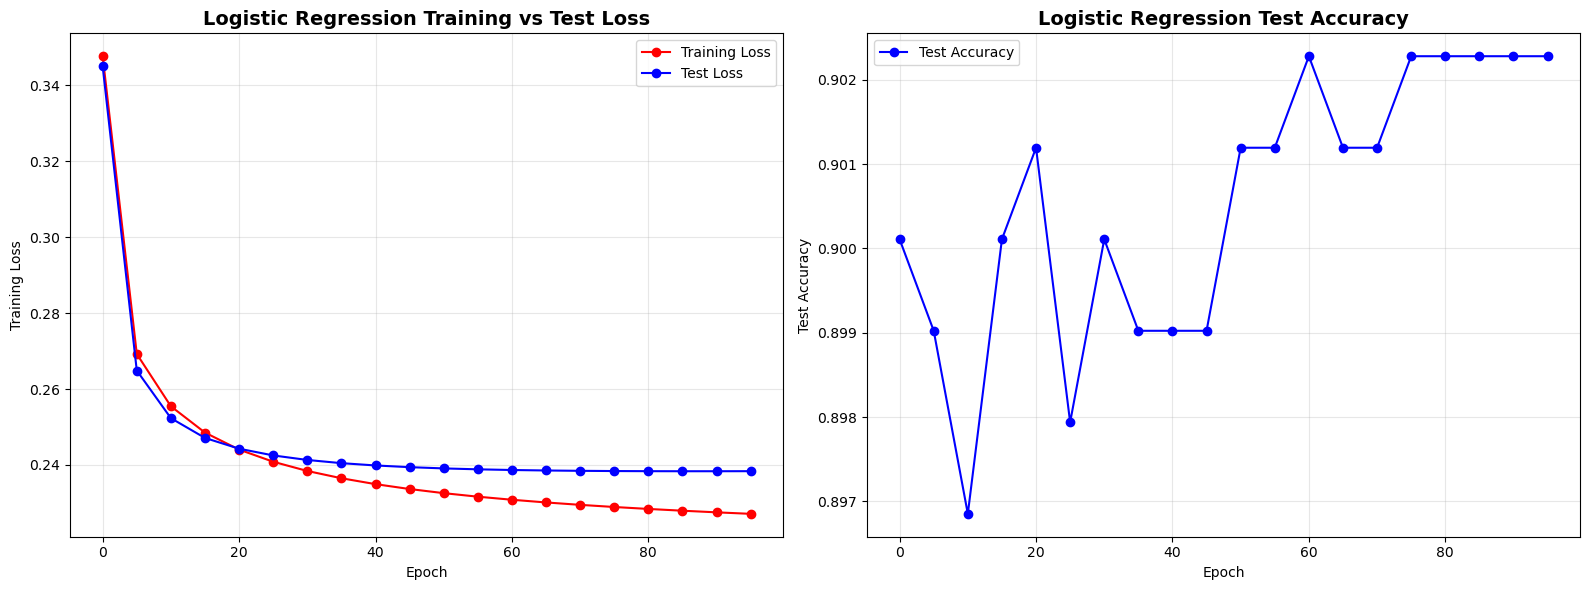

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(epoch_lr, train_loss_lr, label='Training Loss', color='red', marker='o')
axes[0].plot(epoch_lr, test_loss_lr, label='Test Loss', color='blue', marker='o')
axes[0].set_title('Logistic Regression Training vs Test Loss', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Training Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epoch_lr, acc_lr, label='Test Accuracy', color='blue', marker='o')
axes[1].set_title('Logistic Regression Test Accuracy', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Test Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Training using Neural Network

In [44]:
#define some constants for neural network training
LR_NN = 0.01
EPOCH_NN = 100

#define neural network class
class NeuralNetwork(nn.Module):
    def __init__(self, features):
        super().__init__()
        self.flatten = nn.Flatten()
        self.stack = nn.Sequential(
            nn.Linear(features, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16,1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.stack(x)
    
#instantiate model, criterion, and optimizer
model_nn = NeuralNetwork(n_features)
criterion_nn = nn.BCELoss()
optimizer_nn = optim.Adam(model_nn.parameters(), LR_NN)
    
def train_neural_network(model, criterion, optimizer, epoch_nn):
    train_loss, test_loss, test_acc, epochs = [], [], [], []

    #training loop
    for epoch in range(epoch_nn):
        optimizer.zero_grad()
        outputs = model(X_train_t)
        loss = criterion(outputs, y_train_t)

        #compute gradients, update parameters
        loss.backward()
        optimizer.step()

        if epoch%5 == 0:
            model.eval()

            with torch.no_grad():
                y_pred = model(X_test_t)
                y_pred_binary = (y_pred >= 0.5).int()
                acc = accuracy_score(y_test_t, y_pred_binary)
                loss_t = criterion(y_pred, y_test_t)

                train_loss.append(loss.item())
                test_loss.append(loss_t.item())
                test_acc.append(acc) 
                epochs.append(epoch)
            
            model.train()

    return train_loss, test_loss, test_acc, epochs

train_loss_nn, test_loss_nn, acc_nn, epoch_nn = train_neural_network(model_nn, criterion_nn, optimizer_nn, EPOCH_NN)

Plot neural network training loss, test loss, and accuracy

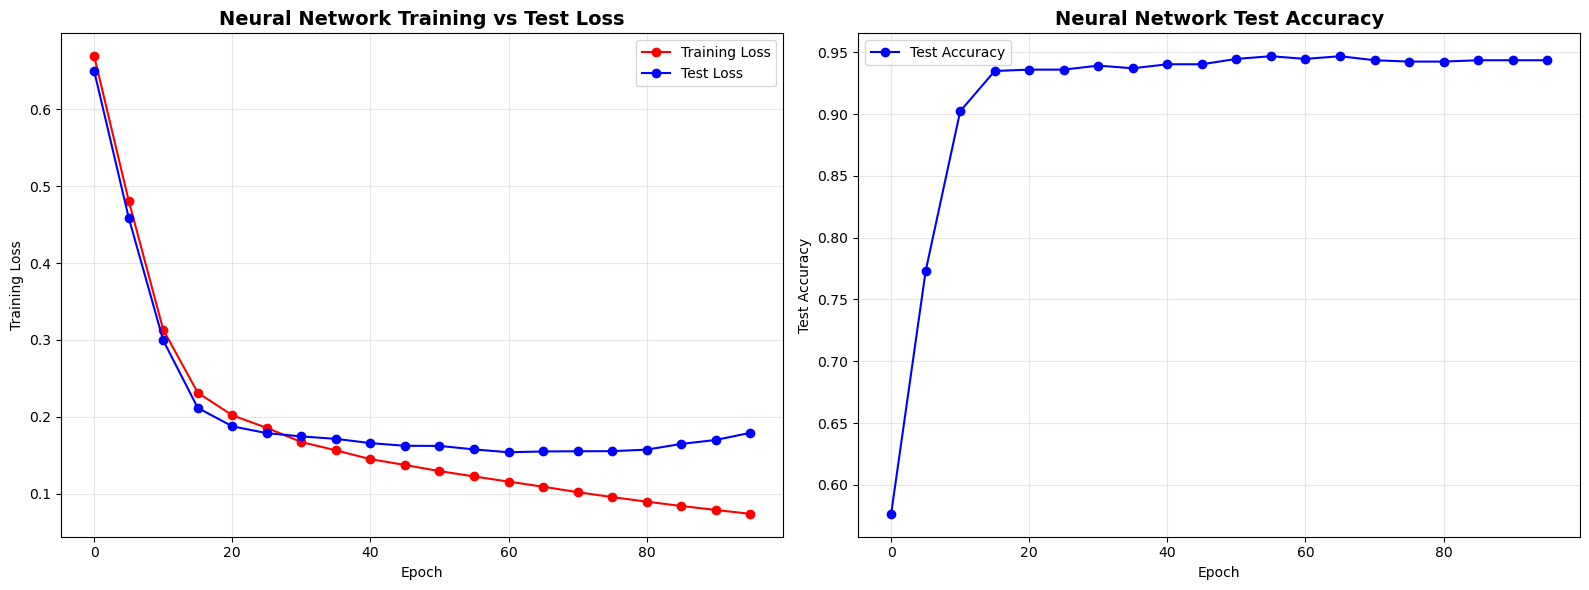

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(epoch_nn, train_loss_nn, label='Training Loss', color='red', marker='o')
axes[0].plot(epoch_nn, test_loss_nn, label='Test Loss', color='blue', marker='o')
axes[0].set_title('Neural Network Training vs Test Loss', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Training Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epoch_nn, acc_nn, label='Test Accuracy', color='blue', marker='o')
axes[1].set_title('Neural Network Test Accuracy', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Test Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Train random forest classifier model

In [53]:
MAX_DEPTH_RF = 2
EPOCH_RF = 100

model = RandomForestClassifier(max_depth=MAX_DEPTH_RF, random_state=random_seed, n_estimators=200)
model.fit(X_train, y_train)

acc_rf = model.score(X_test, y_test)

Compare model accuracy with baseline majority vote performance

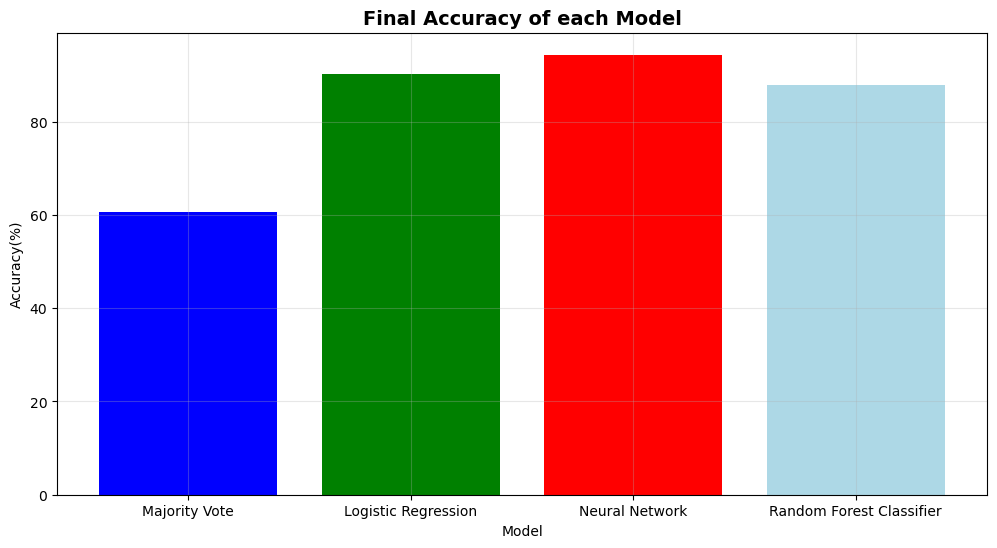

In [54]:
models = ['Majority Vote', 'Logistic Regression', 'Neural Network', 'Random Forest Classifier']
accuracy = [baseline_accuracy*100, acc_lr[-1]*100, acc_nn[-1]*100, acc_rf*100]

plt.figure(figsize=(12, 6))
plt.bar(models, accuracy, color = ['blue', 'green', 'red', 'lightblue'])
plt.title('Final Accuracy of each Model', fontsize=14, fontweight='bold')
plt.xlabel('Model')
plt.ylabel('Accuracy(%)')
plt.grid(True, alpha=0.3)

plt.show()